# Task #3: Survival Modeling and Competing Risks
Done by: Anthony Do

**Question:** How long until a kidney waitlist registration ends in a transplant, and how much does it matter that death or becoming too sick can end the wait first?

**Plan:**
1. **Cox proportional hazards** for time to transplant, evaluated with the **C-index** (Harrell's and Uno's).
2. A **competing-risks** comparison. Death/too sick is a competing event: once it happens, a transplant can never happen. A plain Cox model treats those patients as if they could still be transplanted later, which inflates absolute transplant probabilities. We compare against:
   - **Cause-specific Cox models** (one for transplant, one for death/too sick) combined into a cumulative incidence function (CIF).
   - A **Fine-Gray** subdistribution hazard model for transplant.

**Decisions that carry over from Task #2** (same cohort file, same REM_CD groups, same listing-time features, same temporal split):
- REM_CD groups match the STAR Kidney Student Data Guide (REM_CD Codes tab).
- Features are listing-time only. REGION is out (leaky), ON_DIALYSIS is replaced by dialysis status/vintage at listing, ETHCAT is fairness-only.
- Train on listings before 2021-03-15, test on listings from 2021-03-15 on (Acuity Circles era).

**New for survival (Task #3):**
- **Time axis:** days from INIT_DATE to END_DATE. No 1-year window, so every registration is used; still-waiting rows are censored at the data cut-off.
- **Event of interest (cause 1):** transplanted during this registration (deceased or living donor).
- **Competing event (cause 2):** died, medically unsuitable, or too sick (same adverse codes as Task #2).
- **Censored (cause 0):** still waiting, administrative removals, transplanted elsewhere, and codes 6 (refused transplant) and 12 (condition improved), censored at END_DATE (Deepti).

Only aggregate tables and figures are printed (DUA).

In [1]:
# On Colab: !pip install lifelines scikit-survival
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from lifelines import CoxPHFitter, CoxTimeVaryingFitter, KaplanMeierFitter
from lifelines.utils import concordance_index
from lifelines.statistics import proportional_hazard_test
from sksurv.metrics import concordance_index_ipcw

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42

## 1. Load data

In [2]:
# Local clone of this repo. On Colab, point this at your Drive copy instead.
DATA_PATH = "../../data/kidney_waitlist_analytic.csv.gz"
df = pd.read_csv(DATA_PATH, low_memory=False)
print(df.shape)

(494862, 38)


## 2. CONFIG
Same REM_CD groups and features as Task #2. `CAUSE_OF` maps each group to the survival coding: 1 = transplant, 2 = competing adverse event, 0 = censored.

In [3]:
LIST_DATE_COL  = "INIT_DATE"
END_DATE_COL   = "END_DATE"
REMCD_COL      = "REM_CD"

REMCD_GROUPS = {
    "Adverse (died / too sick)":        {5, 8, 13, 21, 23},
    "Transplanted (this registration)": {2, 4, 15, 18, 19, 41, 42, 43, 44, 45},
    "Transplanted elsewhere":           {3, 14, 22},
    "Administrative":                   {7, 9, 10, 11, 16, 17, 20, 24, 40},
    "Refused transplant":               {6},
    "Condition improved":               {12},
}
CODE_TO_GROUP = {c: g for g, codes in REMCD_GROUPS.items() for c in codes}

TX, ADV, CENS = 1, 2, 0
CAUSE_OF = {
    "Transplanted (this registration)": TX,
    "Adverse (died / too sick)":        ADV,
    "Still waiting":                    CENS,   # censored at the data cut-off
    "Administrative":                   CENS,
    "Transplanted elsewhere":           CENS,   # this registration did not end in its own transplant
    "Refused transplant":               CENS,   # code 6, censored at END_DATE (Deepti)
    "Condition improved":               CENS,   # code 12, censored at END_DATE (Deepti)
    "UNMAPPED":                         CENS,
}

NUMERIC_FEATURES     = ["INIT_AGE", "BMI_TCR", "INIT_CPRA"]
CATEGORICAL_FEATURES = ["GENDER", "ABO", "FUNC_STAT_TCR", "INIT_STAT"]
DERIVED_FEATURES     = ["dialysis_vintage_days", "on_dialysis_at_listing"]
FAIRNESS_ONLY        = ["ETHCAT"]

TEST_START   = "2021-03-15"
HORIZONS     = {"1y": 365, "3y": 3 * 365}   # horizons for absolute-risk checks
UNO_TAU      = 3 * 365                       # Uno's C-index is truncated here
FG_SAMPLE    = 60_000                        # Fine-Gray is fit on a training subsample (data expansion is large)
FG_GRID_DAYS = 30                            # Fine-Gray weight grid

## 3. Build the survival outcome
`T` = days from listing to END_DATE. Same-day endings (T = 0) are set to half a day so they count as events. Rows with missing or negative durations are dropped (data-entry errors, same rule as Task #2).

In [4]:
d = df.copy()
d[LIST_DATE_COL] = pd.to_datetime(d[LIST_DATE_COL], errors="coerce")
d[END_DATE_COL]  = pd.to_datetime(d[END_DATE_COL],  errors="coerce")
d["rem"] = pd.to_numeric(d[REMCD_COL], errors="coerce")
d["remcd_group"] = d["rem"].map(CODE_TO_GROUP)
d.loc[d["rem"].isna(), "remcd_group"] = "Still waiting"
d["remcd_group"] = d["remcd_group"].fillna("UNMAPPED")

cutoff = d.loc[d["rem"].isna(), END_DATE_COL].max()
print("Data cut-off:", cutoff.date())

log = {"start": len(d)}
d = d[d[LIST_DATE_COL].notna()].copy()
d["T"] = (d[END_DATE_COL] - d[LIST_DATE_COL]).dt.days.astype(float)
d = d[d["T"].notna() & (d["T"] >= 0)].copy()
log["after dropping missing/negative durations"] = len(d)
d.loc[d["T"] == 0, "T"] = 0.5
d["cause"] = d["remcd_group"].map(CAUSE_OF).astype(int)

for k, v in log.items(): print(f"{k:45s} {v:>9,}")
print()
print(pd.crosstab(d["remcd_group"], d["cause"].map({TX: "1 transplant", ADV: "2 adverse", CENS: "0 censored"})))

Data cut-off: 2026-07-03


start                                           494,862
after dropping missing/negative durations       494,803

cause                             0 censored  1 transplant  2 adverse
remcd_group                                                          
Administrative                         45331             0          0
Adverse (died / too sick)                  0             0      69685
Condition improved                      2351             0          0
Refused transplant                      2464             0          0
Still waiting                         103300             0          0
Transplanted (this registration)           0        234429          0
Transplanted elsewhere                 37243             0          0


## 4. Features (identical to Task #2)

In [5]:
dial = (d[LIST_DATE_COL] - pd.to_datetime(d["DIALYSIS_DATE"], errors="coerce")).dt.days
d["on_dialysis_at_listing"] = (dial >= 0).astype(int)
d["dialysis_vintage_days"]  = dial.where(dial >= 0, 0)
d["ABO"] = d["ABO"].replace({"A1": "A", "A2": "A", "A1B": "AB", "A2B": "AB"})

num_cols = NUMERIC_FEATURES + DERIVED_FEATURES
cat_cols = list(CATEGORICAL_FEATURES)
for c in cat_cols:
    d[c] = d[c].astype(str).str.replace(r"\.0$", "", regex=True).where(d[c].notna(), np.nan)
assert not set(num_cols + cat_cols) & {"REGION", "ON_DIALYSIS", "ETHCAT"}, "a removed feature slipped back in"
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

Numeric: ['INIT_AGE', 'BMI_TCR', 'INIT_CPRA', 'dialysis_vintage_days', 'on_dialysis_at_listing']
Categorical: ['GENDER', 'ABO', 'FUNC_STAT_TCR', 'INIT_STAT']


## 5. Train/test split and preprocessing
Same temporal split as Task #2. Preprocessing is fit on training rows only. For Cox models the one-hot encoder drops one reference level per category, so each hazard ratio reads "vs. the reference". The reference is the **most common training level** (for example FUNC_STAT_TCR 2080 = 80% Karnofsky), not the alphabetically first one, which here would be a tiny, unusual group and makes every other level look extreme. Levels with fewer than 500 training rows are folded into an "infrequent" level to keep the fit stable.

In [6]:
is_test = (d[LIST_DATE_COL] >= pd.Timestamp(TEST_START)).values
train, test = d.loc[~is_test].copy(), d.loc[is_test].copy()

ref_levels = [train[c].fillna("Missing").mode()[0] for c in cat_cols]
print("Reference levels:", dict(zip(cat_cols, ref_levels)))

prep = ColumnTransformer(sparse_threshold=0, verbose_feature_names_out=False, transformers=[
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                      ("onehot", OneHotEncoder(drop=ref_levels, min_frequency=500,
                                               handle_unknown="infrequent_if_exist"))]), cat_cols),
])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)   # unseen test levels go to "infrequent", as intended
    prep.fit(train[num_cols + cat_cols])
    Xtr = pd.DataFrame(prep.transform(train[num_cols + cat_cols]), columns=prep.get_feature_names_out(), index=train.index)
    Xte = pd.DataFrame(prep.transform(test[num_cols + cat_cols]),  columns=prep.get_feature_names_out(), index=test.index)
const = Xtr.columns[Xtr.std() == 0]
Xtr, Xte = Xtr.drop(columns=const), Xte.drop(columns=const)

def describe(part, name):
    c = part["cause"].value_counts(normalize=True)
    print(f"{name}: {len(part):,} registrations | transplant {c.get(TX, 0):.1%} | adverse {c.get(ADV, 0):.1%} | "
          f"censored {c.get(CENS, 0):.1%} | median follow-up {part['T'].median():.0f} days")
describe(train, "Train"); describe(test, "Test ")
print("Model columns:", Xtr.shape[1])

Reference levels: {'GENDER': 'M', 'ABO': 'O', 'FUNC_STAT_TCR': '2080', 'INIT_STAT': '4010'}


Train: 240,054 registrations | transplant 54.3% | adverse 20.0% | censored 25.7% | median follow-up 642 days
Test : 254,749 registrations | transplant 40.9% | adverse 8.5% | censored 50.7% | median follow-up 318 days
Model columns: 25


## 6. Why competing risks matter: Kaplan-Meier vs. Aalen-Johansen
The naive estimate of "probability of transplant by time t" is `1 − KM(t)`, where deaths are treated as censored. That assumes patients who died would have kept the same chance of a transplant later, which is impossible. The Aalen-Johansen estimator accounts for the competing event and gives the actual cumulative incidence. The gap between the two curves is the bias a plain Cox model inherits when it is used for absolute probabilities.

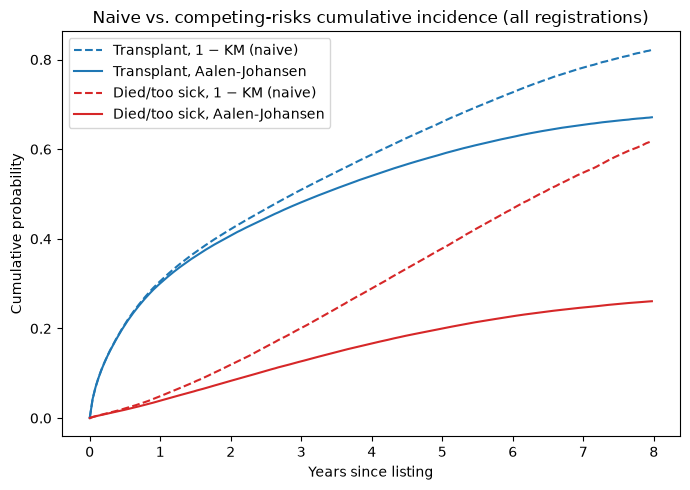

,transplant_1-KM,transplant_AJ,adverse_1-KM,adverse_AJ,transplant_overestimate
1 year,0.306,0.301,0.049,0.039,0.005
3 years,0.510,0.482,0.201,0.127,0.028
5 years,0.661,0.589,0.379,0.200,0.072


In [7]:
def aalen_johansen(T, cause, times):
    # Cumulative incidence of transplant and adverse events at each time in `times`.
    T, cause = np.asarray(T, float), np.asarray(cause)
    t_u, inv = np.unique(T, return_inverse=True)
    d_tx  = np.bincount(inv, weights=(cause == TX),  minlength=len(t_u))
    d_adv = np.bincount(inv, weights=(cause == ADV), minlength=len(t_u))
    n_out = np.bincount(inv, minlength=len(t_u))
    at_risk = len(T) - np.concatenate([[0], np.cumsum(n_out)[:-1]])
    surv = np.cumprod(1 - (d_tx + d_adv) / at_risk)
    surv_prev = np.concatenate([[1.0], surv[:-1]])
    cif_tx, cif_adv = np.cumsum(surv_prev * d_tx / at_risk), np.cumsum(surv_prev * d_adv / at_risk)
    idx = np.searchsorted(t_u, times, side="right") - 1
    pick = lambda a: np.where(idx >= 0, a[np.clip(idx, 0, None)], 0.0)
    return pick(cif_tx), pick(cif_adv)

def one_minus_km(T, event, times):
    km = KaplanMeierFitter().fit(T, event)
    return 1 - km.survival_function_at_times(times).values

grid_days = np.arange(0, 8 * 365 + 1, 15)
aj_tx, aj_adv = aalen_johansen(d["T"], d["cause"], grid_days)
km_tx  = one_minus_km(d["T"], d["cause"] == TX,  grid_days)
km_adv = one_minus_km(d["T"], d["cause"] == ADV, grid_days)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(grid_days / 365, km_tx,  "C0--", label="Transplant, 1 − KM (naive)")
ax.plot(grid_days / 365, aj_tx,  "C0-",  label="Transplant, Aalen-Johansen")
ax.plot(grid_days / 365, km_adv, "C3--", label="Died/too sick, 1 − KM (naive)")
ax.plot(grid_days / 365, aj_adv, "C3-",  label="Died/too sick, Aalen-Johansen")
ax.set_xlabel("Years since listing"); ax.set_ylabel("Cumulative probability")
ax.set_title("Naive vs. competing-risks cumulative incidence (all registrations)")
ax.legend(); plt.tight_layout(); plt.show()

yrs = np.array([1, 3, 5]) * 365
a_tx, a_adv = aalen_johansen(d["T"], d["cause"], yrs)
nonpar = pd.DataFrame({
    "transplant_1-KM": one_minus_km(d["T"], d["cause"] == TX, yrs), "transplant_AJ": a_tx,
    "adverse_1-KM": one_minus_km(d["T"], d["cause"] == ADV, yrs),   "adverse_AJ": a_adv,
}, index=["1 year", "3 years", "5 years"])
nonpar["transplant_overestimate"] = nonpar["transplant_1-KM"] - nonpar["transplant_AJ"]
nonpar.round(3)

## 7. Cox proportional hazards for time to transplant
Event = transplant; everything else (including death/too sick) is censored. Fitting Cox this way estimates the **cause-specific hazard** of transplant: the transplant rate among patients who are still alive and waiting. That is a valid model for *ranking* who gets transplanted sooner; it is only the conversion to absolute probabilities that needs the competing-risks correction (section 9). A small ridge penalty (0.001) keeps the fit stable with many one-hot columns.

In [8]:
def fit_cox(X, part, event_cause, penalizer=0.001):
    frame = X.assign(T=part["T"].values, E=(part["cause"].values == event_cause).astype(int))
    return CoxPHFitter(penalizer=penalizer).fit(frame, duration_col="T", event_col="E")

cox_tx = fit_cox(Xtr, train, TX)
hr = cox_tx.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].rename(
    columns={"exp(coef)": "HR", "exp(coef) lower 95%": "HR_low", "exp(coef) upper 95%": "HR_high"})
print("Hazard ratios for transplant (numeric features are per 1 SD; categories vs. their reference level).")
print("HR > 1 = transplanted sooner. 10 largest effects in each direction:")
hr.sort_values("HR").iloc[np.r_[0:10, -10:0]].round(3)

Hazard ratios for transplant (numeric features are per 1 SD; categories vs. their reference level).
HR > 1 = transplanted sooner. 10 largest effects in each direction:


,HR,HR_low,HR_high,p
covariate,,,,
INIT_STAT_4099,0.708,0.698,0.718,0.000
FUNC_STAT_TCR_2100,0.840,0.821,0.860,0.000
INIT_AGE,0.876,0.870,0.881,0.000
on_dialysis_at_listing,0.929,0.923,0.935,0.000
INIT_CPRA,0.948,0.942,0.953,0.000
FUNC_STAT_TCR_998,0.952,0.914,0.992,0.019
FUNC_STAT_TCR_2090,0.960,0.946,0.975,0.000
FUNC_STAT_TCR_2070,0.970,0.955,0.985,0.000
missingindicator_BMI_TCR,0.987,0.981,0.994,0.000


### 7b. C-index on the test set
- **Harrell's C:** among comparable pairs, the share where the patient with higher predicted transplant hazard was transplanted first. 0.5 = random, 1 = perfect. Target: ≥ 0.72.
- **Uno's C (τ = 3 years):** same idea, but reweights pairs by the inverse probability of censoring, so it is less sensitive to how much of the test set is censored. The test set (post-2021 listings) has much shorter follow-up than training, so Uno's is the more honest number here.
- **Stability over time:** Harrell's C by test listing year.

In [9]:
def surv_array(event, T):
    return np.array(list(zip(event.astype(bool), T)), dtype=[("event", bool), ("time", float)])

def c_indexes(part, risk, event_cause, train_part=train):
    T, E = part["T"].values, (part["cause"].values == event_cause)
    harrell = concordance_index(T, -risk, E)
    uno = concordance_index_ipcw(surv_array(train_part["cause"].values == event_cause, train_part["T"].values),
                                 surv_array(E, T), risk, tau=UNO_TAU)[0]
    return harrell, uno

lp_tx_te = cox_tx.predict_log_partial_hazard(Xte).values
h, u = c_indexes(test, lp_tx_te, TX)
print(f"Cox, time to transplant | Harrell's C = {h:.3f} | Uno's C (tau = 3y) = {u:.3f} | target >= 0.72")

yr = test[LIST_DATE_COL].dt.year.values
by_year = pd.DataFrame([{"listing_year": y_, "n": int((yr == y_).sum()),
                         "transplant_share": (test["cause"].values[yr == y_] == TX).mean(),
                         "harrell_C": concordance_index(test["T"].values[yr == y_], -lp_tx_te[yr == y_],
                                                        test["cause"].values[yr == y_] == TX)}
                        for y_ in sorted(np.unique(yr))])
by_year.round(3)

Cox, time to transplant | Harrell's C = 0.646 | Uno's C (tau = 3y) = 0.641 | target >= 0.72


,listing_year,n,transplant_share,harrell_C
0,2021,34405,0.533,0.648
1,2022,44439,0.512,0.645
2,2023,47001,0.479,0.636
3,2024,49631,0.418,0.633
4,2025,53230,0.303,0.640
5,2026,26043,0.139,0.671


### 7c. Proportional hazards check
Cox assumes each feature multiplies the hazard by a constant factor over the whole wait. The Schoenfeld-residual test checks this on the same model refit on a 20,000-row training sample. With this much data almost every feature shows *some* violation, so the test statistic (how strong the violation is) matters more than the p-value.

In [10]:
# lifelines runs the test on the model's own training frame, so the same model is refit on the sample.
ph_idx = train.sample(20_000, random_state=RANDOM_STATE).index
ph_frame = Xtr.loc[ph_idx].assign(T=train.loc[ph_idx, "T"].values,
                                  E=(train.loc[ph_idx, "cause"].values == TX).astype(int))
ph_model = CoxPHFitter(penalizer=0.001).fit(ph_frame, duration_col="T", event_col="E")
ph = proportional_hazard_test(ph_model, ph_frame, time_transform="rank").summary
ph = ph[["test_statistic", "p"]].sort_values("test_statistic", ascending=False)
print(f"Features with p < 0.05: {(ph['p'] < 0.05).sum()} of {len(ph)}")
ph.head(10).round(4)

Features with p < 0.05: 15 of 25


,test_statistic,p
dialysis_vintage_days,144.8979,0.0000
FUNC_STAT_TCR_4100,54.6755,0.0000
INIT_STAT_4099,44.0098,0.0000
FUNC_STAT_TCR_2020,38.6609,0.0000
INIT_AGE,28.1031,0.0000
FUNC_STAT_TCR_4090,23.1629,0.0000
FUNC_STAT_TCR_4080,14.6381,0.0001
FUNC_STAT_TCR_infrequent_sklearn,10.9511,0.0009
FUNC_STAT_TCR_2040,9.7630,0.0018
FUNC_STAT_TCR_2030,9.4717,0.0021


## 8. Cause-specific Cox for the competing event (died / too sick)
The competing-risks model needs both cause-specific hazards. This one also gives a survival-based view of the Task #2 target (adverse removal), using the full follow-up instead of a fixed 1-year window. Hazard ratios that point in opposite directions in the two models are exactly the features where ignoring competing risks is most misleading.

In [11]:
cox_adv = fit_cox(Xtr, train, ADV)
lp_adv_te = cox_adv.predict_log_partial_hazard(Xte).values
h_adv, u_adv = c_indexes(test, lp_adv_te, ADV)
print(f"Cause-specific Cox, died/too sick | Harrell's C = {h_adv:.3f} | Uno's C (tau = 3y) = {u_adv:.3f}")

both = pd.DataFrame({"HR_transplant": cox_tx.hazard_ratios_, "HR_adverse": cox_adv.hazard_ratios_})
opp = both[(np.log(both["HR_transplant"]) * np.log(both["HR_adverse"]) < 0)
           & ((both["HR_transplant"] - 1).abs() > 0.05) & ((both["HR_adverse"] - 1).abs() > 0.05)]
print(f"\n{len(opp)} features push transplant and adverse hazards in opposite directions (both |HR − 1| > 0.05).")
print("Largest of these (sorted by transplant HR):")
opp.sort_values("HR_transplant").round(3).head(12)

Cause-specific Cox, died/too sick | Harrell's C = 0.631 | Uno's C (tau = 3y) = 0.645

7 features push transplant and adverse hazards in opposite directions (both |HR − 1| > 0.05).
Largest of these (sorted by transplant HR):


,HR_transplant,HR_adverse
covariate,,
INIT_AGE,0.876,1.737
on_dialysis_at_listing,0.929,1.175
FUNC_STAT_TCR_4100,1.764,0.129
FUNC_STAT_TCR_4090,1.802,0.320
FUNC_STAT_TCR_4080,1.933,0.201
FUNC_STAT_TCR_2030,4.842,0.000
FUNC_STAT_TCR_2020,7.606,0.008


## 9. Fine-Gray subdistribution model for transplant
Fine-Gray models the cumulative incidence of transplant directly. Patients who die stay in the risk set after death with a weight that shrinks with the censoring distribution (Fine & Gray, 1999; weighting from Geskus, 2011), so the coefficients describe effects on the *actual* probability of transplant, including the indirect effect through dying first.

lifelines does not have Fine-Gray built in, so it is fit as a weighted Cox model on expanded data (`CoxTimeVaryingFitter` with weights). The expansion is large, so it is fit on a random 60,000-row training sample. Weights are updated every 30 days.

In [12]:
def censoring_survival(T, cause):
    # KM of the censoring distribution G(t) (censoring is the "event").
    km = KaplanMeierFitter().fit(T, cause == CENS)
    return lambda t: km.survival_function_at_times(t).values

def fine_gray_data(X, part, grid_step=FG_GRID_DAYS):
    T, cause = part["T"].values, part["cause"].values
    G = censoring_survival(T, cause)
    base = X.reset_index(drop=True).assign(_id=np.arange(len(X)), start=0.0, stop=T,
                                           E=(cause == TX).astype(int), w=1.0)
    comp = np.where(cause == ADV)[0]
    t_max = T.max()
    pieces = []
    for i in comp:                    # after a competing event, stay at risk with weight G(t) / G(T_i)
        starts = np.arange(T[i], t_max, grid_step)
        stops = np.minimum(starts + grid_step, t_max)
        keep = stops > starts
        starts, stops = starts[keep], stops[keep]
        if len(starts):
            pieces.append(pd.DataFrame({"_id": i, "start": starts, "stop": stops,
                                        "w_raw": G(starts) / max(G(np.array([T[i]]))[0], 1e-12)}))
    extra = pd.concat(pieces, ignore_index=True)
    extra = extra[extra["w_raw"] > 1e-4]
    extra = extra.join(X.reset_index(drop=True), on="_id")
    extra["w"], extra["E"] = extra.pop("w_raw").clip(upper=1), 0
    return pd.concat([base, extra[base.columns]], ignore_index=True)

fg_idx = train.sample(FG_SAMPLE, random_state=RANDOM_STATE).index
fg_df = fine_gray_data(Xtr.loc[fg_idx], train.loc[fg_idx])
print(f"Fine-Gray: {FG_SAMPLE:,} registrations expanded to {len(fg_df):,} rows")

fg = CoxTimeVaryingFitter(penalizer=0.001)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fg.fit(fg_df, id_col="_id", event_col="E", start_col="start", stop_col="stop", weights_col="w")
lp_fg_te = fg.predict_log_partial_hazard(Xte).values

# Cause-specific transplant Cox refit on the same subsample, to separate "Fine-Gray vs. Cox" from "less data".
cox_tx_sub = fit_cox(Xtr.loc[fg_idx], train.loc[fg_idx], TX)

shr = pd.DataFrame({"HR_cause_specific": cox_tx_sub.hazard_ratios_, "SHR_fine_gray": np.exp(fg.params_)})
shr["shift"] = shr["SHR_fine_gray"] / shr["HR_cause_specific"]
print("Features where Fine-Gray and cause-specific Cox disagree most (SHR / HR):")
shr.reindex(shr["shift"].sub(1).abs().sort_values(ascending=False).index).head(10).round(3)

Fine-Gray: 60,000 registrations expanded to 1,320,416 rows


Features where Fine-Gray and cause-specific Cox disagree most (SHR / HR):


,HR_cause_specific,SHR_fine_gray,shift
covariate,,,
FUNC_STAT_TCR_2020,6.853,2.450,0.358
FUNC_STAT_TCR_2030,5.592,2.147,0.384
FUNC_STAT_TCR_infrequent_sklearn,2.259,1.712,0.758
FUNC_STAT_TCR_2040,1.265,1.116,0.882
FUNC_STAT_TCR_4080,1.974,1.744,0.883
FUNC_STAT_TCR_4090,1.799,1.614,0.897
ABO_AB,2.128,1.952,0.917
FUNC_STAT_TCR_4100,1.771,1.630,0.921
FUNC_STAT_TCR_2100,0.868,0.934,1.076


## 10. Comparing the approaches on the test set
Three ways to get a patient's probability of transplant by 1 and 3 years:

| Approach | How absolute risk is computed |
|---|---|
| **Naive Cox** | `1 − exp(−H_tx(t))`, the transplant Cox model alone, treating death as censoring |
| **Cause-specific CIF** | `Σ S(t⁻) · ΔH_tx(t)`, where `S` uses *both* cause-specific hazards, so patients who die stop accruing transplant probability |
| **Fine-Gray** | `1 − exp(−H_sub(t))`, from the subdistribution model |

**Ranking metrics:**
- **Cause-specific C** (Harrell): competing events treated as censored. This is the number most papers report.
- **Competing-risks C** (Wolbers et al., 2009): patients who died stay comparable as "never transplanted", so a model is rewarded for ranking them below everyone who was transplanted. This matches the question patients actually ask: *will I get a transplant?*

**Calibration:** predicted vs. observed (Aalen-Johansen) cumulative incidence at 1 and 3 years, overall and by decile of predicted risk.

In [13]:
def step_at(series, grid):
    # Value of a step function (index = time) at each grid point.
    idx = np.searchsorted(series.index.values, grid, side="right") - 1
    return np.where(idx >= 0, series.values[np.clip(idx, 0, None)], 0.0)

def cif_cause_specific(lp_tx, lp_adv, grid, chunk=20_000):
    H_tx  = step_at(cox_tx.baseline_cumulative_hazard_.iloc[:, 0], grid)
    H_adv = step_at(cox_adv.baseline_cumulative_hazard_.iloc[:, 0], grid)
    dH_tx = np.diff(np.concatenate([[0.0], H_tx]))
    out = []
    for s in range(0, len(lp_tx), chunk):
        r_tx, r_adv = np.exp(lp_tx[s:s + chunk])[:, None], np.exp(lp_adv[s:s + chunk])[:, None]
        S = np.exp(-(r_tx * H_tx + r_adv * H_adv))
        S_prev = np.hstack([np.ones((S.shape[0], 1)), S[:, :-1]])
        out.append(np.cumsum(S_prev * r_tx * dH_tx, axis=1))
    return np.vstack(out)

grid = np.unique(np.concatenate([np.arange(0, max(HORIZONS.values()) + 1, 7.0), list(HORIZONS.values())]))
h_idx = {k: np.searchsorted(grid, v) for k, v in HORIZONS.items()}
cif_cs = cif_cause_specific(lp_tx_te, lp_adv_te, grid)
H_tx_h  = step_at(cox_tx.baseline_cumulative_hazard_.iloc[:, 0], np.array(list(HORIZONS.values())))
H_fg_h  = step_at(fg.baseline_cumulative_hazard_.iloc[:, 0],     np.array(list(HORIZONS.values())))

pred = {}
for j, (k, v) in enumerate(HORIZONS.items()):
    pred[("Naive Cox", k)]          = 1 - np.exp(-np.exp(lp_tx_te) * H_tx_h[j])
    pred[("Cause-specific CIF", k)] = cif_cs[:, h_idx[k]]
    pred[("Fine-Gray", k)]          = 1 - np.exp(-np.exp(lp_fg_te) * H_fg_h[j])

def competing_risks_c(part, risk):
    T = part["T"].values.copy(); cause = part["cause"].values
    T[cause == ADV] = np.inf            # died first = never transplanted, comparable with everyone
    T[np.isinf(T)] = part["T"].max() * 10
    return concordance_index(T, -risk, cause == TX)

obs = dict(zip(HORIZONS, aalen_johansen(test["T"], test["cause"], np.array(list(HORIZONS.values())))[0]))
rows = []
for approach, risk_for_rank in [("Naive Cox", lp_tx_te), ("Cause-specific CIF", pred[("Cause-specific CIF", "3y")]),
                                ("Fine-Gray", lp_fg_te)]:
    h_c, u_c = c_indexes(test, risk_for_rank, TX)
    row = {"approach": approach, "harrell_C": h_c, "uno_C_3y": u_c,
           "competing_risks_C": competing_risks_c(test, risk_for_rank)}
    for k in HORIZONS:
        row[f"mean_pred_{k}"] = pred[(approach, k)].mean()
        row[f"observed_AJ_{k}"] = obs[k]
    rows.append(row)
comparison = pd.DataFrame(rows).set_index("approach")
print(f"Test set: {len(test):,} registrations. Fine-Gray trained on a {FG_SAMPLE:,}-row sample, the others on all {len(train):,}.")
print(f"Cause-specific transplant Cox refit on the same sample: Harrell's C = {c_indexes(test, cox_tx_sub.predict_log_partial_hazard(Xte).values, TX)[0]:.3f}")
comparison.round(3)

Test set: 254,749 registrations. Fine-Gray trained on a 60,000-row sample, the others on all 240,054.


Cause-specific transplant Cox refit on the same sample: Harrell's C = 0.647


,harrell_C,uno_C_3y,competing_risks_C,mean_pred_1y,observed_AJ_1y,mean_pred_3y,observed_AJ_3y
approach,,,,,,,
Naive Cox,0.646,0.641,0.641,0.278,0.328,0.479,0.514
Cause-specific CIF,0.636,0.631,0.632,0.274,0.328,0.451,0.514
Fine-Gray,0.630,0.627,0.628,0.273,0.328,0.448,0.514


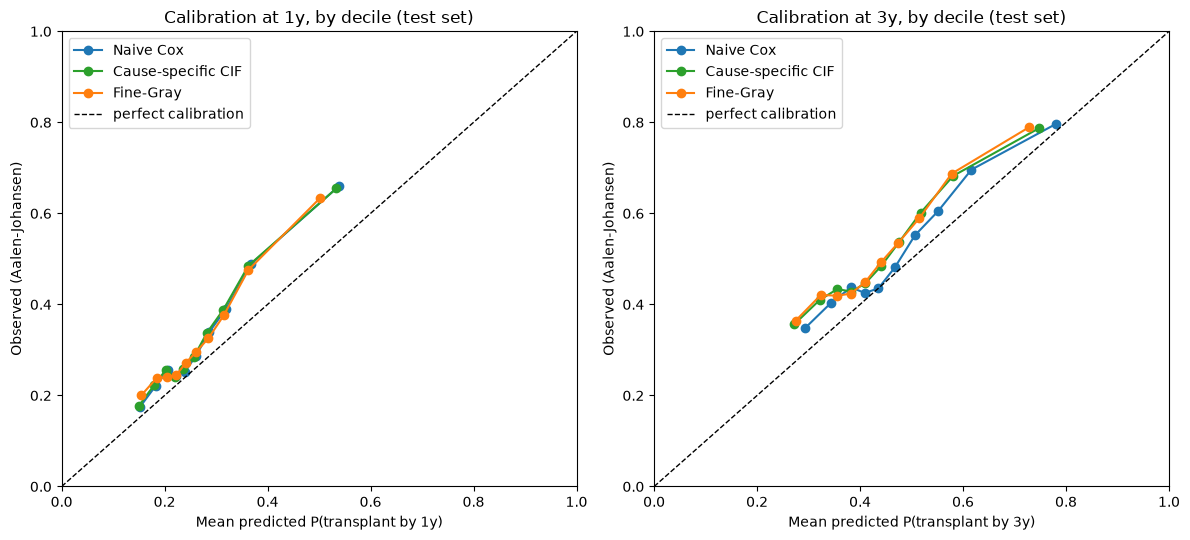

Mean absolute calibration error across deciles (lower is better):


,1y,3y
Naive Cox,0.054,0.039
Cause-specific CIF,0.057,0.066
Fine-Gray,0.057,0.069


In [14]:
def decile_calibration(p, part, horizon_days, bins=10):
    dec = pd.qcut(pd.Series(p).rank(method="first"), bins, labels=False).values
    rows = []
    for b in range(bins):
        m = dec == b
        rows.append({"decile": b + 1, "mean_predicted": p[m].mean(),
                     "observed_AJ": aalen_johansen(part["T"].values[m], part["cause"].values[m],
                                                   np.array([horizon_days]))[0][0]})
    return pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
calib = {}
for ax, (k, v) in zip(axes, HORIZONS.items()):
    for approach, color in [("Naive Cox", "C0"), ("Cause-specific CIF", "C2"), ("Fine-Gray", "C1")]:
        t = decile_calibration(pred[(approach, k)], test, v)
        calib[(approach, k)] = t
        ax.plot(t["mean_predicted"], t["observed_AJ"], "o-", color=color, label=approach)
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel(f"Mean predicted P(transplant by {k})"); ax.set_ylabel("Observed (Aalen-Johansen)")
    ax.set_title(f"Calibration at {k}, by decile (test set)"); ax.legend()
plt.tight_layout(); plt.savefig("task3_transplant_calibration.png", dpi=150); plt.show()

ece = pd.DataFrame({k: {a: (calib[(a, k)]["mean_predicted"] - calib[(a, k)]["observed_AJ"]).abs().mean()
                        for a in ["Naive Cox", "Cause-specific CIF", "Fine-Gray"]} for k in HORIZONS})
print("Mean absolute calibration error across deciles (lower is better):")
ece.round(3)

### 10b. Same calibration check inside the training era
On the test set every approach *under*-predicts transplant, because transplant rates rose after 2021 (Acuity Circles era) and the models only saw pre-2021 listings. That era shift is in the opposite direction of the competing-risks bias, so on the test set the naive model's over-prediction accidentally cancels part of it. To see the competing-risks effect by itself, the same comparison is run on the training-era registrations, where there is no era shift.

In [15]:
lp_tx_tr, lp_adv_tr, lp_fg_tr = (m.predict_log_partial_hazard(Xtr).values for m in (cox_tx, cox_adv, fg))
cif_cs_tr = cif_cause_specific(lp_tx_tr, lp_adv_tr, grid)
obs_tr = dict(zip(HORIZONS, aalen_johansen(train["T"], train["cause"], np.array(list(HORIZONS.values())))[0]))
in_era = pd.DataFrame({
    f"{k}": {"Naive Cox": (1 - np.exp(-np.exp(lp_tx_tr) * H_tx_h[j])).mean(),
             "Cause-specific CIF": cif_cs_tr[:, h_idx[k]].mean(),
             "Fine-Gray": (1 - np.exp(-np.exp(lp_fg_tr) * H_fg_h[j])).mean(),
             "Observed (Aalen-Johansen)": obs_tr[k]}
    for j, k in enumerate(HORIZONS)})
print("Training era (pre-2021 listings): mean predicted vs. observed P(transplant by t)")
in_era.round(3)

Training era (pre-2021 listings): mean predicted vs. observed P(transplant by t)


,1y,3y
Naive Cox,0.285,0.489
Cause-specific CIF,0.282,0.464
Fine-Gray,0.281,0.460
Observed (Aalen-Johansen),0.274,0.454


## 11. Fairness check: C-index by subgroup
Project criterion: performance within 0.05 across demographic and regional fields. Uses the competing-risks C of the cause-specific CIF (3-year) on the test set. ETHCAT is used here only, never as a feature. Subgroups with fewer than 1,000 test registrations are skipped.

In [16]:
ETHCAT_LABELS = {1: "White", 2: "Black", 4: "Hispanic", 5: "Asian", 6: "Amer Ind/Alaska Native",
                 7: "Native Hawaiian/Pacific Isl.", 9: "Multiracial", 998: "Unknown"}
risk_cs = pred[("Cause-specific CIF", "3y")]
groups = {
    "ETHCAT": test["ETHCAT"].map(lambda v: ETHCAT_LABELS.get(int(v), str(v)) if pd.notna(v) else "Missing"),
    "GENDER": test["GENDER"],
    "ABO":    test["ABO"],
    "age":    pd.cut(test["INIT_AGE"], [-1, 17, 34, 49, 64, 200], labels=["<18", "18-34", "35-49", "50-64", "65+"]),
}
overall = competing_risks_c(test, risk_cs)
rows = []
for field, g in groups.items():
    g = g.astype(str).values
    for level in pd.unique(g):
        m = g == level
        if m.sum() >= 1000:
            c = competing_risks_c(test.loc[m], risk_cs[m])
            rows.append({"field": field, "group": level, "n": int(m.sum()),
                         "transplant_share": (test["cause"].values[m] == TX).mean(), "C": c, "gap_vs_overall": c - overall})
fair = pd.DataFrame(rows).sort_values(["field", "n"], ascending=[True, False])
spread = fair.groupby("field")["C"].agg(lambda s: s.max() - s.min()).rename("max_minus_min_C")
print(f"Overall competing-risks C: {overall:.3f}")
print(spread.round(3).to_string(), "\n")
print(fair.round(3).to_string(index=False))

Overall competing-risks C: 0.632
field
ABO       0.012
ETHCAT    0.068
GENDER    0.008
age       0.062 

 field                        group      n  transplant_share     C  gap_vs_overall
   ABO                            O 126294             0.362 0.616          -0.016
   ABO                            A  80449             0.475 0.608          -0.024
   ABO                            B  38348             0.380 0.608          -0.024
   ABO                           AB   9658             0.581 0.620          -0.013
ETHCAT                        White  99037             0.438 0.614          -0.018
ETHCAT                        Black  76644             0.395 0.656           0.023
ETHCAT                     Hispanic  52561             0.392 0.645           0.013
ETHCAT                        Asian  19155             0.366 0.628          -0.004
ETHCAT                  Multiracial   2257             0.416 0.653           0.021
ETHCAT       Amer Ind/Alaska Native   1964             0.388 0.66

## 12. Extension: does listing center explain the rest?
Waiting time for a kidney varies a lot by transplant center (local organ supply, how aggressively a center accepts offers). Task #2 dropped REGION as leaky and noted the STAR guide suggests LISTING_CTR_CODE instead, encoded on training data only. Here each center gets one number, its **observed-to-expected transplant ratio**: transplants observed at that center divided by what the section 7 model expects for its patients, shrunk toward 1 for small centers (`log((O + 50) / (E + 50))`). Training rows use 5-fold cross-fitting, so a row's own outcome never feeds its center value. Test rows use the value from all training rows; centers not seen in training get 0 (average).

This is reported as a sensitivity result, not the main model: center is a proxy for geography and allocation practice, so it raises the fairness and "re-learning historical allocation" concerns from the project overview.

In [17]:
from sklearn.model_selection import KFold

def center_log_oe(part, X, K=50):
    H0 = step_at(cox_tx.baseline_cumulative_hazard_.iloc[:, 0], part["T"].values)
    expected = np.exp(cox_tx.predict_log_partial_hazard(X).values) * H0
    g = pd.DataFrame({"ctr": part["LISTING_CTR_CODE"].values, "O": (part["cause"].values == TX), "E": expected}).groupby("ctr").sum()
    return np.log((g["O"] + K) / (g["E"] + K))

ctr_tr = np.zeros(len(train))
for fit_i, apply_i in KFold(5, shuffle=True, random_state=RANDOM_STATE).split(train):
    m = center_log_oe(train.iloc[fit_i], Xtr.iloc[fit_i])
    ctr_tr[apply_i] = train["LISTING_CTR_CODE"].iloc[apply_i].map(m).fillna(0).values
ctr_te = test["LISTING_CTR_CODE"].map(center_log_oe(train, Xtr)).fillna(0).values
mu, sd = ctr_tr.mean(), ctr_tr.std()
Xtr_c, Xte_c = Xtr.assign(center_log_oe=(ctr_tr - mu) / sd), Xte.assign(center_log_oe=(ctr_te - mu) / sd)
print(f"Centers: {train['LISTING_CTR_CODE'].nunique()} in training; "
      f"{(~test['LISTING_CTR_CODE'].isin(train['LISTING_CTR_CODE'])).mean():.2%} of test rows are at unseen centers")

cox_tx_c = fit_cox(Xtr_c, train, TX)
lp_c = cox_tx_c.predict_log_partial_hazard(Xte_c).values
h_c, u_c = c_indexes(test, lp_c, TX)
center_cmp = pd.DataFrame({
    "harrell_C": [h, h_c], "uno_C_3y": [u, u_c],
    "competing_risks_C": [competing_risks_c(test, lp_tx_te), competing_risks_c(test, lp_c)],
}, index=["Cox, listing-time features", "Cox + listing-center O/E"])
print(f"HR per 1 SD of center O/E: {cox_tx_c.hazard_ratios_['center_log_oe']:.2f}")
center_cmp.round(3)

Centers: 248 in training; 1.08% of test rows are at unseen centers


HR per 1 SD of center O/E: 1.57


,harrell_C,uno_C_3y,competing_risks_C
"Cox, listing-time features",0.646,0.641,0.641
Cox + listing-center O/E,0.679,0.675,0.674


## 13. Summary (printed from the results above)

In [18]:
c = comparison
print(f"Cohort: {len(d):,} registrations (train {len(train):,}, test {len(test):,}).")
print(f"Naive 1 − KM overstates the 3-year transplant probability by {nonpar.loc['3 years', 'transplant_overestimate']:.3f} "
      f"({nonpar.loc['3 years', 'transplant_1-KM']:.3f} vs. {nonpar.loc['3 years', 'transplant_AJ']:.3f} Aalen-Johansen).")
print(f"Cox time to transplant: Harrell's C {h:.3f}, Uno's C (3y) {u:.3f} (target >= 0.72).")
print(f"Cause-specific Cox, died/too sick: Harrell's C {h_adv:.3f}.")
for a in c.index:
    print(f"{a:20s} competing-risks C {c.loc[a, 'competing_risks_C']:.3f} | mean predicted 3y {c.loc[a, 'mean_pred_3y']:.3f} "
          f"vs observed {c.loc[a, 'observed_AJ_3y']:.3f} | decile calibration error 3y {ece.loc[a, '3y']:.3f}")
print(f"Fairness (competing-risks C spread, max − min): " + ", ".join(f"{k} {v:.3f}" for k, v in spread.items()))
print(f"Adding listing-center O/E: Harrell's C {h:.3f} -> {h_c:.3f}, Uno's C {u:.3f} -> {u_c:.3f}.")

Cohort: 494,803 registrations (train 240,054, test 254,749).
Naive 1 − KM overstates the 3-year transplant probability by 0.028 (0.510 vs. 0.482 Aalen-Johansen).
Cox time to transplant: Harrell's C 0.646, Uno's C (3y) 0.641 (target >= 0.72).
Cause-specific Cox, died/too sick: Harrell's C 0.631.
Naive Cox            competing-risks C 0.641 | mean predicted 3y 0.479 vs observed 0.514 | decile calibration error 3y 0.039
Cause-specific CIF   competing-risks C 0.632 | mean predicted 3y 0.451 vs observed 0.514 | decile calibration error 3y 0.066
Fine-Gray            competing-risks C 0.628 | mean predicted 3y 0.448 vs observed 0.514 | decile calibration error 3y 0.069
Fairness (competing-risks C spread, max − min): ABO 0.012, ETHCAT 0.068, GENDER 0.008, age 0.062
Adding listing-center O/E: Harrell's C 0.646 -> 0.679, Uno's C 0.641 -> 0.675.


## 14. Write-up
**Cox PH, time to transplant.** Harrell's C = 0.646 and Uno's C (3 years) = 0.641 on post-2021 listings, below the 0.72 target. It is stable across test listing years (0.633 to 0.648 for 2021 to 2025). Strongest effects, as hazard ratios vs. the reference level: blood type AB (2.05) and A (1.49) vs. O, pediatric functional status (about 1.8 to 1.9), dialysis vintage (1.27 per SD), inactive at listing (INIT_STAT 4099: 0.71), and age (0.88 per SD). The proportional hazards assumption is violated for some features, mostly dialysis vintage and functional status. With 240K rows small violations are significant, but dialysis vintage has by far the largest test statistic, likely because waiting-time credit counts dialysis time and its effect changes over the wait.

**Competing risks matter for absolute probabilities, not much for ranking.**
- Nonparametric (all registrations): naive 1 − KM says 51.0% are transplanted by 3 years; Aalen-Johansen says 48.2%. The gap grows to 7.2 points by 5 years (66.1% vs. 58.9%). The naive estimate for died/too sick is even worse: 37.9% vs. 20.0% at 5 years.
- Model-based, inside the training era (section 10b): naive Cox predicts 48.9% transplanted by 3 years vs. 45.4% observed (+3.5 points). Cause-specific CIF (46.4%) and Fine-Gray (46.0%) are within 1 point.
- On the test set all three under-predict (observed 51.4% at 3 years) because transplant rates rose after 2021. That shift runs opposite to the competing-risks bias, so the naive model looks better calibrated on the test set (decile error 0.039 vs. 0.066) for the wrong reason. **Recommendation:** use the cause-specific CIF (or Fine-Gray) for any "probability of transplant by year X" number shown to patients, and recalibrate it on recent listings before use.
- Ranking: the cause-specific transplant Cox ranks best (competing-risks C 0.641). The cause-specific CIF (0.632) and Fine-Gray (0.628) are slightly lower, so adding the death model does not help *rank* who gets transplanted. Fine-Gray was fit on a 60K sample, but a cause-specific Cox on the same sample scores 0.647, so the sample size is not the reason.
- Where the two views disagree: age and dialysis at listing lower the transplant hazard *and* raise the death hazard, so they hurt a patient's real chance of transplant twice. Fine-Gray captures this (age SHR 0.815 vs. cause-specific HR 0.878 on the same sample).

**Cause-specific Cox, died/too sick:** Harrell's C = 0.631 with full follow-up, in line with the Task #2 1-year classifier (ROC-AUC about 0.67).

**Fairness (criterion: within 0.05):** sex (spread 0.008) and blood type (0.012) pass. Ethnicity (0.068) and age (0.062) do not, but the spread comes from small groups: Native Hawaiian/Pacific Islander (n = 1,354, C = 0.682) and pediatric (<18, n = 6,138, C = 0.595). Among the four largest ethnicity groups the spread is 0.042. The model ranks White patients least well (0.614) and Black patients best (0.656).

**Listing center (extension, section 12):** adding a cross-fitted center observed/expected transplant ratio raises Harrell's C from 0.646 to 0.679 (HR 1.57 per SD). Center explains more than any patient feature, which says a lot about geographic variation in access. It is still below 0.72, and since it encodes where a patient lists rather than who they are, the team should decide whether it belongs in a patient-facing model or only in the "geographic and systemic factors" analysis.

**Limits and open questions:**
- FUNC_STAT_TCR 2020/2030 (Karnofsky 20 to 30%) show a 5 to 8× *higher* transplant hazard with almost no deaths. These registrations have a median wait of only 15 to 23 days, so they look like listings created close to a transplant offer, not very sick patients getting priority. Worth asking Deepti whether to exclude them or treat them as a separate group.
- Test follow-up is short (median 318 days), and 2026 listings have very little of it. Uno's C handles the censoring but horizon estimates past 3 years rest on training-era data.
- "Transplanted elsewhere" is censored, so this models transplant *at the listing center's registration*. Treating it as a transplant instead is a reasonable sensitivity check.
- Living-donor transplants are counted as transplant events. A deceased-donor-only outcome would better match the allocation question.